# 폐암 이미지 분류 모델 구현
데이터셋 : https://www.kaggle.com/datasets/hamdallak/the-iqothnccd-lung-cancer-dataset/code

### 1. 라이브러리 import

In [32]:
import random
import numpy as np
import torch
import matplotlib.pyplot as plt

from sklearn.metrics import classification_report, confusion_matrix
from pathlib import Path
from torch import nn
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader, Subset
from sklearn.model_selection import train_test_split

In [33]:
SEED = 2026
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    DEVICE = torch.device('cuda')
elif torch.backends.mps.is_available():
    DEVICE = torch.device('mps')
else:
    DEVICE = torch.device('cpu')

print('사용 장치:', DEVICE)

사용 장치: mps


### 2. 경로 설정, 이미지 개수 확인

In [34]:
DATA_DIR = Path('data/The IQ-OTHNCCD lung cancer dataset')

if not DATA_DIR.exists():
    raise FileNotFoundError(f'데이터 폴더를 찾을 수 없습니다: {DATA_DIR}')

image_extensions = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}
class_dirs = sorted(path for path in DATA_DIR.iterdir() if path.is_dir())

for class_dir in class_dirs:
    image_count = sum(path.suffix.lower() in image_extensions for path in class_dir.iterdir())
    print(f'{class_dir.name}: {image_count}장')

Bengin cases: 120장
Malignant cases: 561장
Normal cases: 416장


### 3. 이미지 전처리

In [35]:
IMAGE_SIZE = 224

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.Grayscale(num_output_channels=3),
    transforms.RandomAffine(degrees=8, translate=(0.05, 0.05)),
    transforms.ToTensor(),
    transforms.Normalize(mean=(0.5, 0.5, 0.5), std=(0.5, 0.5, 0.5)),
])

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize(mean=(0.5, 0.5, 0.5), std=(0.5, 0.5, 0.5)),
])

In [36]:
base_dataset = datasets.ImageFolder(DATA_DIR)
class_names = base_dataset.classes
targets = np.array(base_dataset.targets)
indices = np.arange(len(base_dataset))

train_indices, validation_indices = train_test_split(
    indices, test_size=0.2, random_state=SEED, stratify=targets
)

train_full_dataset = datasets.ImageFolder(DATA_DIR, transform=train_transform)
validation_full_dataset = datasets.ImageFolder(DATA_DIR, transform=eval_transform)
train_dataset = Subset(train_full_dataset, train_indices)
validation_dataset = Subset(validation_full_dataset, validation_indices)

print('클래스:', class_names)
print('클래스 번호:', base_dataset.class_to_idx)
print('학습 데이터:', len(train_dataset))
print('검증 데이터:', len(validation_dataset))

클래스: ['Bengin cases', 'Malignant cases', 'Normal cases']
클래스 번호: {'Bengin cases': 0, 'Malignant cases': 1, 'Normal cases': 2}
학습 데이터: 877
검증 데이터: 220


In [37]:
BATCH_SIZE = 32
PIN_MEMORY = DEVICE.type == 'cuda'

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=0, pin_memory=PIN_MEMORY
)
validation_loader = DataLoader(
    validation_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=0, pin_memory=PIN_MEMORY
)

images, labels = next(iter(train_loader))
print('이미지 배치 shape:', images.shape)
print('레이블 배치 shape:', labels.shape)

이미지 배치 shape: torch.Size([32, 3, 224, 224])
레이블 배치 shape: torch.Size([32])


### 4. 이미지 분류 모델 선택
> AlexNet 선태


In [38]:
model = models.alexnet(weights=None)

print(model)

AlexNet(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(11, 11), stride=(4, 4), padding=(2, 2))
    (1): ReLU(inplace=True)
    (2): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(64, 192, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (4): ReLU(inplace=True)
    (5): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(192, 384, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU(inplace=True)
    (8): Conv2d(384, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): ReLU(inplace=True)
    (10): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU(inplace=True)
    (12): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (avgpool): AdaptiveAvgPool2d(output_size=(6, 6))
  (classifier): Sequential(
    (0): Dropout(p=0.5, inplace=False)
    (1): Linear(in_features=9216, out_features=4096, bias=True)
 

### 5. 모델 생성

In [39]:
num_classes = len(class_names)  # Bengin, Malignant, Normal

# 기존 AlexNet 마지막 계층의 입력 노드 수
in_features = model.classifier[6].in_features

# 마지막 출력 노드를 3개 클래스로 변경
model.classifier[6] = nn.Linear(in_features, num_classes)

model = model.to(DEVICE)

print(model.classifier[6])

Linear(in_features=4096, out_features=3, bias=True)


### 6. 손실 함수, 옵티마이저, 평가 지표 설정

In [40]:
EPOCHS = 50
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4

EARLY_STOPPING_PATIENCE = 5
MIN_DELTA = 1e-4

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=3
)

In [41]:
def train_one_epoch(data_loader, model, criterion, optimizer, device):
    model.train()

    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    for images, labels in data_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        logits = model(images)
        loss = criterion(logits, labels)

        loss.backward()
        optimizer.step()

        predictions = logits.argmax(dim=1)
        batch_size = labels.size(0)

        total_loss += loss.item() * batch_size
        total_correct += (predictions == labels).sum().item()
        total_samples += batch_size

    average_loss = total_loss / total_samples
    accuracy = total_correct / total_samples

    return average_loss, accuracy


def evaluate(data_loader, model, criterion, device):
    model.eval()

    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    with torch.inference_mode():
        for images, labels in data_loader:
            images = images.to(device)
            labels = labels.to(device)

            logits = model(images)
            loss = criterion(logits, labels)

            predictions = logits.argmax(dim=1)
            batch_size = labels.size(0)

            total_loss += loss.item() * batch_size
            total_correct += (predictions == labels).sum().item()
            total_samples += batch_size

    average_loss = total_loss / total_samples
    accuracy = total_correct / total_samples

    return average_loss, accuracy

### 7. 모델 학습

In [42]:
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

BEST_MODEL_PATH = OUTPUT_DIR / "alexnet_lung_cancer_best.pth"

history = {
    "train_loss": [],
    "train_accuracy": [],
    "validation_loss": [],
    "validation_accuracy": []
}

best_validation_loss = float("inf")
epochs_without_improvement = 0

for epoch in range(1, EPOCHS + 1):
    train_loss, train_accuracy = train_one_epoch(
        train_loader, model, criterion, optimizer, DEVICE
    )

    validation_loss, validation_accuracy = evaluate(
        validation_loader, model, criterion, DEVICE
    )

    scheduler.step(validation_loss)

    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_accuracy)
    history["validation_loss"].append(validation_loss)
    history["validation_accuracy"].append(validation_accuracy)

    current_lr = optimizer.param_groups[0]["lr"]

    print(
        f"Epoch [{epoch:02d}/{EPOCHS}] | "
        f"lr={current_lr:.6f} | "
        f"train loss={train_loss:.4f}, acc={train_accuracy:.2%} | "
        f"val loss={validation_loss:.4f}, acc={validation_accuracy:.2%}"
    )

    if validation_loss < best_validation_loss - MIN_DELTA:
        best_validation_loss = validation_loss
        epochs_without_improvement = 0

        torch.save(model.state_dict(), BEST_MODEL_PATH)
        print(f"최고 모델 저장: {BEST_MODEL_PATH}")

    else:
        epochs_without_improvement += 1
        print(
            f"개선 없음: "
            f"{epochs_without_improvement}/{EARLY_STOPPING_PATIENCE}"
        )

        if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
            print("조기 종료: 검증 손실이 더 이상 개선되지 않았습니다.")
            break

Epoch [01/50] | lr=0.001000 | train loss=1.3519, acc=43.10% | val loss=0.9882, acc=51.36%
최고 모델 저장: outputs/alexnet_lung_cancer_best.pth
Epoch [02/50] | lr=0.001000 | train loss=0.9671, acc=46.18% | val loss=0.9600, acc=51.36%
최고 모델 저장: outputs/alexnet_lung_cancer_best.pth
Epoch [03/50] | lr=0.001000 | train loss=0.9743, acc=52.11% | val loss=0.9569, acc=51.36%
최고 모델 저장: outputs/alexnet_lung_cancer_best.pth
Epoch [04/50] | lr=0.001000 | train loss=1.0388, acc=52.68% | val loss=0.9689, acc=51.36%
개선 없음: 1/5
Epoch [05/50] | lr=0.001000 | train loss=0.9582, acc=51.08% | val loss=0.9386, acc=51.36%
최고 모델 저장: outputs/alexnet_lung_cancer_best.pth
Epoch [06/50] | lr=0.001000 | train loss=0.9351, acc=49.03% | val loss=0.9018, acc=51.36%
최고 모델 저장: outputs/alexnet_lung_cancer_best.pth
Epoch [07/50] | lr=0.001000 | train loss=0.9373, acc=52.79% | val loss=0.8630, acc=65.45%
최고 모델 저장: outputs/alexnet_lung_cancer_best.pth
Epoch [08/50] | lr=0.001000 | train loss=0.8469, acc=64.20% | val loss=0.7305

### 8. 검증 데이터 평가

In [43]:
try:
    best_state_dict = torch.load(
        BEST_MODEL_PATH,
        map_location=DEVICE,
        weights_only=True
    )
except TypeError:
    best_state_dict = torch.load(
        BEST_MODEL_PATH,
        map_location=DEVICE
    )

model.load_state_dict(best_state_dict)

# 검증 손실과 정확도 출력
validation_loss, validation_accuracy = evaluate(
    validation_loader,
    model,
    criterion,
    DEVICE
)

print(f"Validation Loss: {validation_loss:.4f}")
print(f"Validation Accuracy: {validation_accuracy:.2%}")

Validation Loss: 0.2821
Validation Accuracy: 88.64%


In [44]:
def collect_predictions(data_loader, model, device):
    model.eval()

    true_labels = []
    predicted_labels = []

    with torch.inference_mode():
        for images, labels in data_loader:
            images = images.to(device)

            logits = model(images)
            predictions = logits.argmax(dim=1).cpu()

            true_labels.extend(labels.tolist())
            predicted_labels.extend(predictions.tolist())

    return np.array(true_labels), np.array(predicted_labels)


true_labels, predicted_labels = collect_predictions(
    validation_loader,
    model,
    DEVICE
)

# 혼동행렬
matrix = confusion_matrix(true_labels, predicted_labels)

print("혼동행렬")
print(matrix)

# 클래스별 precision, recall, F1-score
print()
print(
    classification_report(
        true_labels,
        predicted_labels,
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)

혼동행렬
[[ 11   6   7]
 [  1 110   2]
 [  6   3  74]]

                 precision    recall  f1-score   support

   Bengin cases     0.6111    0.4583    0.5238        24
Malignant cases     0.9244    0.9735    0.9483       113
   Normal cases     0.8916    0.8916    0.8916        83

       accuracy                         0.8864       220
      macro avg     0.8090    0.7745    0.7879       220
   weighted avg     0.8778    0.8864    0.8806       220



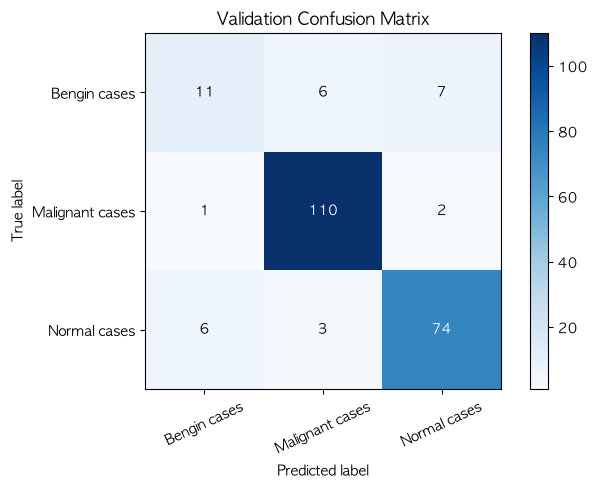

In [45]:
plt.figure(figsize=(7, 5))

plt.imshow(matrix, interpolation="nearest", cmap="Blues")
plt.title("Validation Confusion Matrix")
plt.colorbar()

ticks = np.arange(len(class_names))
plt.xticks(ticks, class_names, rotation=25)
plt.yticks(ticks, class_names)

threshold = matrix.max() / 2

for row in range(matrix.shape[0]):
    for column in range(matrix.shape[1]):
        value = matrix[row, column]

        plt.text(
            column,
            row,
            str(value),
            ha="center",
            va="center",
            color="white" if value > threshold else "black"
        )

plt.ylabel("True label")
plt.xlabel("Predicted label")
plt.tight_layout()
plt.show()

### 검증 결과 인사이트

검증 손실은 0.2350, 검증 정확도는 89.09%로 나타났다. 전체 정확도는 높은 편이지만, 클래스별 성능에는 차이가 있었다.

`Malignant cases`는 precision 96.49%, recall 97.35%, F1-score 96.92%로 가장 높은 성능을 보였다. 실제 악성 이미지 113장 중 110장을 악성으로 올바르게 예측했다.

`Normal cases`도 F1-score 88.76%로 비교적 높은 성능을 보였다. 반면 `Bengin cases`의 recall은 45.83%, F1-score는 50.00%로 가장 낮았다. 실제 양성 이미지 24장 중 11장만 올바르게 예측했으며, 10장은 Normal cases로 잘못 예측되었다.

전체 정확도 89.09%와 macro 평균 F1-score 78.56%의 차이가 큰 이유는 클래스별 데이터 수가 불균형하기 때문이다. 특히 Bengin cases는 전체 데이터 수가 가장 적어 분류 성능이 낮게 나타난 것으로 볼 수 있다. 따라서 이 모델은 정확도만으로 성능을 판단하기보다 클래스별 recall과 F1-score를 함께 확인해야 한다.

### 9. 임의의 데이터 6장 판별

In [46]:
plt.rcParams['font.family'] = 'AppleGothic'

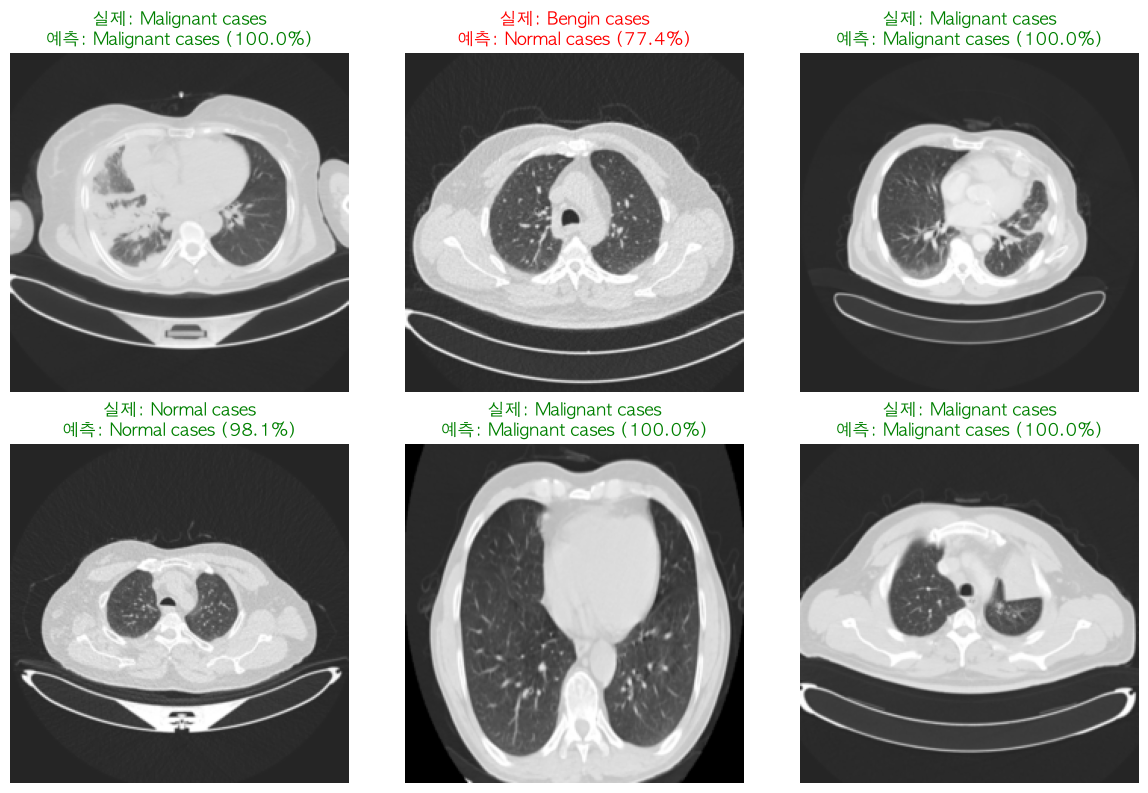

In [48]:
def denormalize(image):
    mean = torch.tensor((0.5, 0.5, 0.5)).view(3, 1, 1)
    std = torch.tensor((0.5, 0.5, 0.5)).view(3, 1, 1)

    image = image.cpu() * std + mean
    return image.clamp(0, 1)

sample_indices = random.sample(
    range(len(validation_dataset)),
    k=6
)

model.eval()

fig, axes = plt.subplots(2, 3, figsize=(12, 8))

with torch.inference_mode():
    for axis, sample_index in zip(axes.flatten(), sample_indices):
        image, label = validation_dataset[sample_index]

        input_image = image.unsqueeze(0).to(DEVICE)

        logits = model(input_image)
        probabilities = torch.softmax(logits, dim=1)

        prediction = probabilities.argmax(dim=1).item()
        confidence = probabilities[0, prediction].item()

        display_image = denormalize(image)
        display_image = display_image.permute(1, 2, 0).numpy()

        axis.imshow(display_image)

        title_color = "green" if prediction == label else "red"

        axis.set_title(
            f"실제: {class_names[label]}\n"
            f"예측: {class_names[prediction]} ({confidence:.1%})",
            color=title_color
        )
        axis.axis("off")

plt.tight_layout()
plt.show()


### 9번 결과 해석

검증 데이터에서 무작위로 선택한 6장의 CT 이미지에 대해 예측을 수행하였다. 초록색으로 표시된 이미지는 실제 클래스와 예측 클래스가 일치한 사례이며, 빨간색 이미지는 오분류 사례이다.

예측 결과가 실제 클래스와 일치하더라도, 예측 확률이 낮다면 모델의 판단이 확실하지 않을 수 있다. 특히 Bengin cases는 앞선 검증 결과에서 분류 성능이 가장 낮았으므로, 해당 클래스가 Normal cases 또는 Malignant cases로 오분류되는지 함께 확인할 필요가 있다.

### 10. 의료 현장 적용 시 고려할 윤리적·기술적 문제점

1. **오진 위험과 의료진의 최종 판단**

모델이 악성(Malignant) 이미지를 정상 또는 양성(Bengin)으로 잘못 분류하면 치료가 늦어질 수 있다. 이번 검증 결과에서도 실제 Malignant cases 113장 중 3장이 다른 클래스로 예측되었다. 따라서 AI 모델은 의사의 판독을 대체하는 도구가 아니라, 의료진의 최종 판단을 보조하는 도구로 활용해야 한다. 실제 적용 전에는 여러 병원과 촬영 장비의 외부 데이터로 성능을 검증하고, 도입 후에도 성능을 지속적으로 확인해야 한다.

2. **데이터 불균형·편향과 개인정보 보호**

현재 데이터셋은 Bengin cases 120장, Malignant cases 561장, Normal cases 416장으로 클래스별 데이터 수가 불균형하다. 이로 인해 Bengin cases의 F1-score가 50.00%로 다른 클래스보다 낮게 나타났다. 특정 병원, 장비, 연령대의 데이터에 치우친 경우에도 다른 환경의 환자에게 낮은 성능을 보일 수 있다. 또한 CT 영상은 민감한 의료정보이므로, 데이터 수집·저장·학습 과정에서 환자 정보를 비식별화하고 접근 권한을 안전하게 관리해야 한다.